In [25]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density

**load data**

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
dhs_array = dhs.to_numpy()
del dhs

(733, 3591898)


In [16]:
del dhs_array

In [3]:
#results from fill in 0.01%
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)

In [17]:
del updated_dhs_array_all_delta_0001_2_cycles
del updated_dhs_array_all_delta_0001_1_cycle

In [4]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [5]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_added_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_removed_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

first_01_added_calls_delta_vals = first_01_added_calls_delta_biosample_DHS[0, :]
first_01_added_calls_biosample_inds = first_01_added_calls_delta_biosample_DHS[1, :].astype(int)
first_01_added_calls_DHS_inds = first_01_added_calls_delta_biosample_DHS[2, :].astype(int)

first_01_removed_calls_delta_vals = first_01_removed_calls_delta_biosample_DHS[0, :]
first_01_removed_calls_biosample_inds = first_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
first_01_removed_calls_DHS_inds = first_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [8]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_added_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'rb')
second_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_removed_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'rb')
second_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

second_01_added_calls_delta_vals = second_01_added_calls_delta_biosample_DHS[0, :]
second_01_added_calls_biosample_inds = second_01_added_calls_delta_biosample_DHS[1, :].astype(int)
second_01_added_calls_DHS_inds = second_01_added_calls_delta_biosample_DHS[2, :].astype(int)

second_01_removed_calls_delta_vals = second_01_removed_calls_delta_biosample_DHS[0, :]
second_01_removed_calls_biosample_inds = second_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
second_01_removed_calls_DHS_inds = second_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [9]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_added_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'rb')
third_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_removed_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'rb')
third_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

third_01_added_calls_delta_vals = third_01_added_calls_delta_biosample_DHS[0, :]
third_01_added_calls_biosample_inds = third_01_added_calls_delta_biosample_DHS[1, :].astype(int)
third_01_added_calls_DHS_inds = third_01_added_calls_delta_biosample_DHS[2, :].astype(int)

third_01_removed_calls_delta_vals = third_01_removed_calls_delta_biosample_DHS[0, :]
third_01_removed_calls_biosample_inds = third_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
third_01_removed_calls_DHS_inds = third_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

**Removing 1 to 1 interactions**

In [10]:
previous_call_value_first_01_added_calls = []
for biosample, dhs in zip(first_01_added_calls_biosample_inds, first_01_added_calls_DHS_inds):
    previous_call_value_first_01_added_calls.append(dhs_array[biosample, dhs])
previous_call_value_first_01_added_calls = np.array(previous_call_value_first_01_added_calls)

first_01_added_calls_previously_0 = np.where(previous_call_value_first_01_added_calls==0)[0]

In [11]:
first_01_added_calls_delta_vals_filtered = first_01_added_calls_delta_vals[first_01_added_calls_previously_0]
first_01_added_calls_biosample_inds_filtered = first_01_added_calls_biosample_inds[first_01_added_calls_previously_0]
first_01_added_calls_DHS_inds_filtered = first_01_added_calls_DHS_inds[first_01_added_calls_previously_0] 

In [12]:
previous_call_value_second_01_added_calls = []
for biosample, dhs in zip(second_01_added_calls_biosample_inds, second_01_added_calls_DHS_inds):
    previous_call_value_second_01_added_calls.append(updated_dhs_array_all_delta_0001_1_cycle[biosample, dhs])
previous_call_value_second_01_added_calls = np.array(previous_call_value_second_01_added_calls)

second_01_added_calls_previously_0 = np.where(previous_call_value_second_01_added_calls==0)[0]

In [13]:
second_01_added_calls_delta_vals_filtered = second_01_added_calls_delta_vals[second_01_added_calls_previously_0]
second_01_added_calls_biosample_inds_filtered = second_01_added_calls_biosample_inds[second_01_added_calls_previously_0]
second_01_added_calls_DHS_inds_filtered = second_01_added_calls_DHS_inds[second_01_added_calls_previously_0]

In [14]:
previous_call_value_third_01_added_calls = []
for biosample, dhs in zip(third_01_added_calls_biosample_inds, third_01_added_calls_DHS_inds):
    previous_call_value_third_01_added_calls.append(updated_dhs_array_all_delta_0001_2_cycles[biosample, dhs])
previous_call_value_third_01_added_calls = np.array(previous_call_value_third_01_added_calls)

third_01_added_calls_previously_0 = np.where(previous_call_value_third_01_added_calls==0)[0]

In [15]:
third_01_added_calls_delta_vals_filtered = third_01_added_calls_delta_vals[third_01_added_calls_previously_0]
third_01_added_calls_biosample_inds_filtered = third_01_added_calls_biosample_inds[third_01_added_calls_previously_0]
third_01_added_calls_DHS_inds_filtered = third_01_added_calls_DHS_inds[third_01_added_calls_previously_0]

**Plotting delta vs peak signal**

In [18]:
#finding peak signal values of removed calls
first_01_removed_calls_peak_signal = []
for i, j in zip(first_01_removed_calls_biosample_inds, first_01_removed_calls_DHS_inds):
    first_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
first_01_removed_calls_peak_signal = np.array(first_01_removed_calls_peak_signal)

second_01_removed_calls_peak_signal = []
for i, j in zip(second_01_removed_calls_biosample_inds, second_01_removed_calls_DHS_inds):
    second_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
second_01_removed_calls_peak_signal = np.array(second_01_removed_calls_peak_signal)
    
third_01_removed_calls_peak_signal = []
for i, j in zip(third_01_removed_calls_biosample_inds, third_01_removed_calls_DHS_inds):
    third_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
third_01_removed_calls_peak_signal = np.array(third_01_removed_calls_peak_signal)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%')

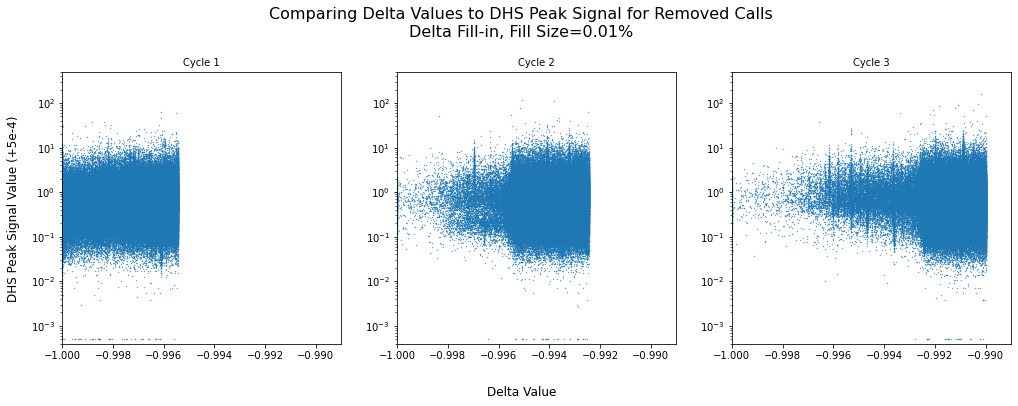

In [19]:
data = [first_01_removed_calls_delta_vals, 
        first_01_removed_calls_peak_signal+0.0005, 
        second_01_removed_calls_delta_vals, 
        second_01_removed_calls_peak_signal+0.0005, 
        third_01_removed_calls_delta_vals, 
        third_01_removed_calls_peak_signal+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.1)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([-1, -.989])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('log')

fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

In [64]:
#finding average signal value of DHS of removed calls
first_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[first_01_removed_calls_DHS_inds]['mean_signal'])
second_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[second_01_removed_calls_DHS_inds]['mean_signal'])
third_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[third_01_removed_calls_DHS_inds]['mean_signal'])

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%')

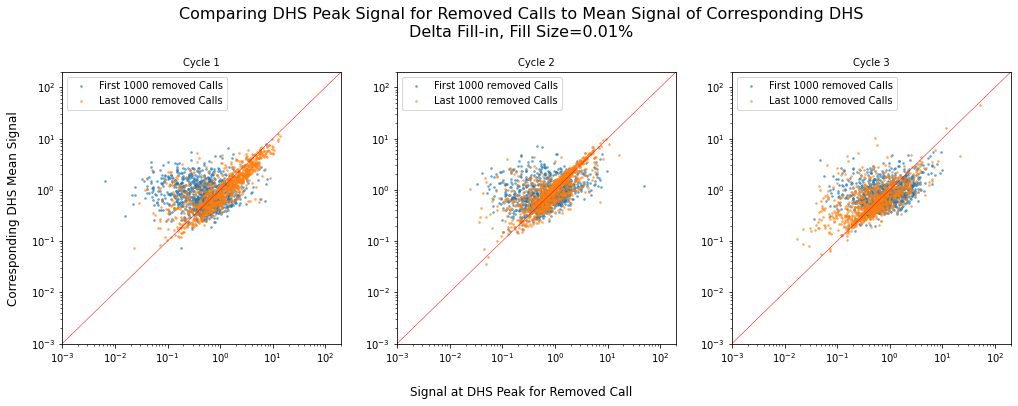

In [65]:
data = [first_01_removed_calls_peak_signal, 
        first_01_removed_calls_DHS_mean_signal, 
        second_01_removed_calls_peak_signal, 
        second_01_removed_calls_DHS_mean_signal, 
        third_01_removed_calls_peak_signal, 
        third_01_removed_calls_DHS_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][:1000], data[(2*ind)+1][:1000], s=3, alpha=0.5)
    scat = ax.scatter(data[2*ind][-1000:], data[(2*ind)+1][-1000:], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

In [20]:
#finding peak signal values of added calls
first_01_added_calls_peak_signal_filtered = []
for i, j in zip(first_01_added_calls_biosample_inds_filtered, first_01_added_calls_DHS_inds_filtered):
    first_01_added_calls_peak_signal_filtered.append(DHS_peak_signal_array[i, j])
first_01_added_calls_peak_signal_filtered = np.array(first_01_added_calls_peak_signal_filtered)

second_01_added_calls_peak_signal_filtered = []
for i, j in zip(second_01_added_calls_biosample_inds_filtered, second_01_added_calls_DHS_inds_filtered):
    second_01_added_calls_peak_signal_filtered.append(DHS_peak_signal_array[i, j])
second_01_added_calls_peak_signal_filtered = np.array(second_01_added_calls_peak_signal_filtered)
    
third_01_added_calls_peak_signal_filtered = []
for i, j in zip(third_01_added_calls_biosample_inds_filtered, third_01_added_calls_DHS_inds_filtered):
    third_01_added_calls_peak_signal_filtered.append(DHS_peak_signal_array[i, j])
third_01_added_calls_peak_signal_filtered = np.array(third_01_added_calls_peak_signal_filtered)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Added Calls (Previously 0)\nDelta Fill-in, Fill Size=0.01%')

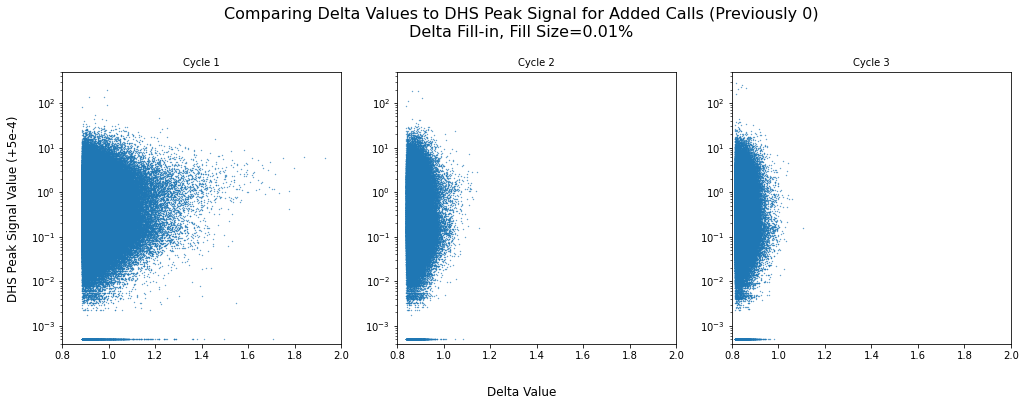

In [21]:
data = [first_01_added_calls_delta_vals_filtered, 
        first_01_added_calls_peak_signal_filtered+0.0005, 
        second_01_added_calls_delta_vals_filtered, 
        second_01_added_calls_peak_signal_filtered+0.0005, 
        third_01_added_calls_delta_vals_filtered, 
        third_01_added_calls_peak_signal_filtered+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.1)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.8, 2])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('symlog')

fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Added Calls (Previously 0)\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

In [66]:
#finding average signal value of filtered added calls
first_01_added_calls_DHS_filtered_mean_signal = np.array(DHS_metadata.loc[first_01_added_calls_DHS_inds_filtered]['mean_signal'])
second_01_added_calls_DHS_filtered_mean_signal = np.array(DHS_metadata.loc[second_01_added_calls_DHS_inds_filtered]['mean_signal'])
third_01_added_calls_DHS_filtered_mean_signal = np.array(DHS_metadata.loc[third_01_added_calls_DHS_inds_filtered]['mean_signal'])

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added Calls (Previously 0) to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%')

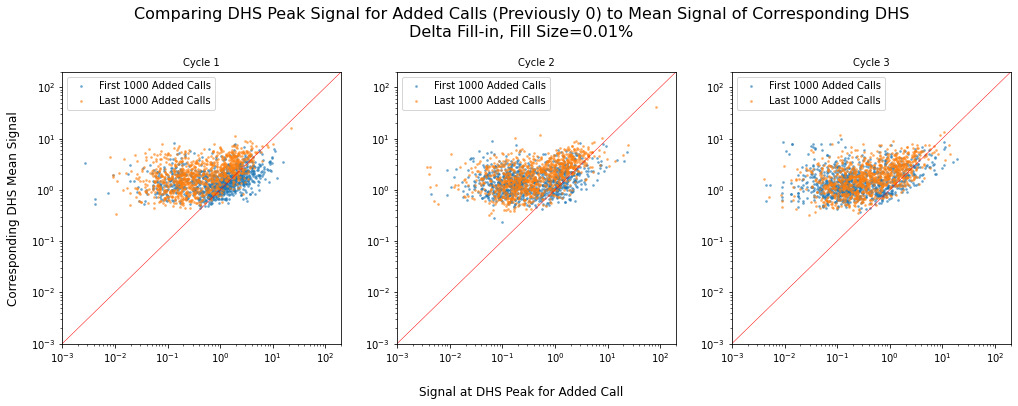

In [68]:
data = [first_01_added_calls_peak_signal_filtered,
        first_01_added_calls_DHS_filtered_mean_signal, 
        second_01_added_calls_peak_signal_filtered, 
        second_01_added_calls_DHS_filtered_mean_signal, 
        third_01_added_calls_peak_signal_filtered, 
        third_01_added_calls_DHS_filtered_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][:1000], data[(2*ind)+1][:1000], s=3, alpha=0.5)
    scat = ax.scatter(data[2*ind][-1000:], data[(2*ind)+1][-1000:], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls (Previously 0) to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

/tmp/ipykernel_192586/2272077700.py:31: MatplotlibDeprecationWarning: Starting from Matplotlib 3.6, colorbar() will steal space from the mappable's axes, rather than from the current axes, to place the colorbar.  To silence this warning, explicitly pass the 'ax' argument to colorbar().
  fig.colorbar(scat, label='Density (points per pixel)')
/tmp/ipykernel_192586/2272077700.py:37: MatplotlibDeprecationWarning: Starting from Matplotlib 3.6, colorbar() will steal space from the mappable's axes, rather than from the current axes, to place the colorbar.  To silence this warning, explicitly pass the 'ax' argument to colorbar().
  fig.colorbar(scat, label='Density (points per pixel)')


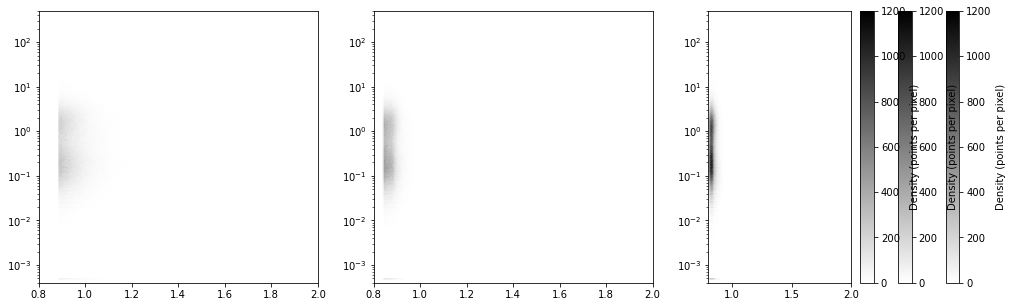

In [88]:
from matplotlib.colors import LinearSegmentedColormap

data = [first_01_added_calls_delta_vals_filtered, 
        first_01_added_calls_peak_signal_filtered+0.0005, 
        second_01_added_calls_delta_vals_filtered, 
        second_01_added_calls_peak_signal_filtered+0.0005, 
        third_01_added_calls_delta_vals_filtered, 
        third_01_added_calls_peak_signal_filtered+0.0005]

white_viridis = LinearSegmentedColormap.from_list('white_viridis', [
    (0, '#ffffff'),
    (1e-20, '#440053'),
    (0.2, '#404388'),
    (0.4, '#2a788e'),
    (0.6, '#21a784'),
    (0.8, '#78d151'),
    (1, '#fde624'),
], N=256)

fig = plt.figure(figsize=(17,5))

fig.patch.set_facecolor('white')
ax1 = fig.add_subplot(1, 3, 1, projection='scatter_density')
ax2 = fig.add_subplot(1, 3, 2, projection='scatter_density')
ax3 = fig.add_subplot(1, 3, 3, projection='scatter_density')

scat = ax1.scatter_density(data[0], data[1], cmap='binary', vmax=1200)
ax1.set_xlim([0.8, 2])
ax1.set_ylim([0.0004, 500])
ax1.set_yscale('log')
fig.colorbar(scat, label='Density (points per pixel)')

scat = ax2.scatter_density(data[2], data[3], cmap='binary', vmax=1200)
ax2.set_xlim([0.8, 2])
ax2.set_ylim([0.0004, 500])
ax2.set_yscale('log')
fig.colorbar(scat, label='Density (points per pixel)')

scat = ax3.scatter_density(data[4], data[5], cmap='binary', vmax=1200)
ax3.set_xlim([0.8, 2])
ax3.set_ylim([0.0004, 500])
ax3.set_yscale('log')

fig.colorbar(scat, label='Density (points per pixel)')